# From RC circuit to spike

**Question:** How does a neuron turn an input current into a train of spikes, and how does its firing rate depend on the current?

**Model (leaky integrate-and-fire, LIF):** the cell membrane is an RC circuit with a battery $u_\mathrm{rest}$ (Gerstner et al., *Neuronal Dynamics*, 2014, Sect. 1.3):

$$\tau_m \frac{du}{dt} = -\,[u(t) - u_\mathrm{rest}] + R\,I(t) \qquad (1.5)$$

When $u$ reaches the threshold $\vartheta$, the neuron fires a spike and $u$ is reset to $u_r$ (Eqs. 1.12, 1.13).

Imports and plot style: numpy for the arrays, matplotlib for the figures, which are saved to `figures/`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Plot style: quiet axes, one blue for the data
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
BLUE = "#2a78d6"  # data
GRAY = "#52514e"  # reference lines and labels
ORANGE = "#eb6834"  # further series, in this order
AQUA = "#1baf7a"
YELLOW = "#eda100"

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

Parameters of the LIF neuron. The units are chosen so that they fit together without conversion: MΩ · nA = mV.

In [2]:
# Units: mV, ms, MOhm, nA
u_rest = -70.0   # resting potential (mV)
theta = -50.0    # firing threshold (mV)
u_reset = -70.0  # value u jumps to after a spike (mV); here = u_rest, as in Fig. 1.9
R = 10.0         # membrane resistance (MOhm)
tau_m = 10.0     # membrane time constant tau_m = R * C (ms)

Simulation with the Euler method: in each small time step `dt`, $u$ changes by `dt` times $du/dt$ from Eq. (1.5); when $u$ reaches the threshold, the spike time is stored and $u$ is reset.

In [3]:
def simulate_lif(I, T=100.0, dt=0.1):
    """Leaky integrate-and-fire neuron with constant input current.

    I  : input current (nA)
    T  : simulated time (ms)
    dt : time step (ms)
    Returns time t (ms), membrane potential u (mV), spike times (ms).
    """
    n_steps = int(round(T / dt))
    t = np.arange(n_steps) * dt
    u = np.empty(n_steps)
    u[0] = u_rest
    spike_times = []

    for k in range(n_steps - 1):
        du = ((-(u[k] - u_rest) + R * I) / tau_m) * dt    # Euler step of Eq. (1.5)
        u[k + 1] = u[k] + du

        if u[k + 1] >= theta:           # threshold reached, Eq. (1.12)
            spike_times.append(t[k + 1])
            u[k + 1] = u_reset          # reset, Eq. (1.13)

    return t, u, np.array(spike_times)

First run: a constant current of 3 nA for 100 ms. The vertical lines only mark the spike times; the LIF model does not describe the shape of a spike (Sect. 1.3).

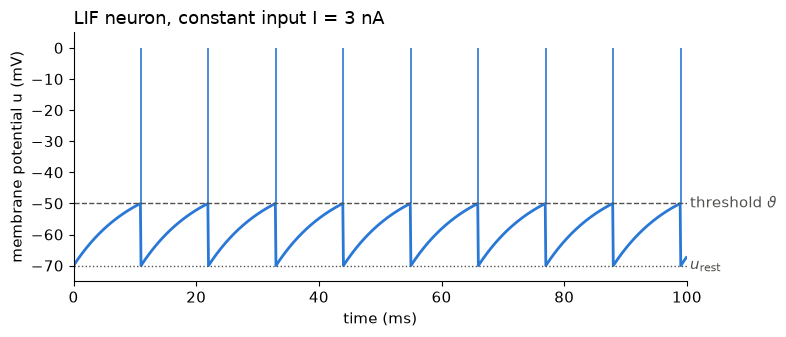

9 spikes in 100 ms


In [4]:
I = 3    # input current (nA)
T = 100.0  # simulated time (ms)
t, u, spike_times = simulate_lif(I, T)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t, u, color=BLUE, lw=2)
ax.vlines(spike_times, theta, 0, color=BLUE, lw=1.2)  # spike times
ax.axhline(theta, color=GRAY, lw=1, ls="--")
ax.axhline(u_rest, color=GRAY, lw=1, ls=":")
ax.text(T + 0.5, theta, r"threshold $\vartheta$", va="center", color=GRAY)
ax.text(T + 0.5, u_rest, r"$u_\mathrm{rest}$", va="center", color=GRAY)
ax.set(xlim=(0, T), ylim=(-75, 5),
       xlabel="time (ms)", ylabel="membrane potential u (mV)")
ax.set_title(f"LIF neuron, constant input I = {I} nA", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / f"lif_trace_{I:g}nA.png", dpi=150)
plt.show()

print(f"{len(spike_times)} spikes in {T:.0f} ms")

Check against the analytical solution: setting $u = \vartheta$ in Eq. (1.7) gives the time from reset to threshold, $T_\mathrm{ISI} = \tau_m \ln\frac{RI}{RI - (\vartheta - u_\mathrm{rest})}$.

In [5]:
T_analytic = tau_m * np.log(R * I / (R * I - (theta - u_rest)))
T_sim = np.diff(spike_times).mean()
print(f"interspike interval: simulation {T_sim:.2f} ms, analytic {T_analytic:.2f} ms")

interspike interval: simulation 11.00 ms, analytic 10.99 ms


## f-I curve

For each constant current, simulate 1 s and count the spikes: the firing rate $f$ is the number of spikes per second (Hz). Below the rheobase $I_\mathrm{rh} = (\vartheta - u_\mathrm{rest})/R$ the voltage never reaches the threshold, so $f = 0$.

In [6]:
currents = np.linspace(0, 5, 51)  # input currents (nA)
T_long = 1000.0                   # 1 s of simulated time (ms)

rates_sim = []
for current in currents:
    _, _, spikes = simulate_lif(current, T_long)
    rates_sim.append(len(spikes) / (T_long / 1000))  # spikes per second (Hz)
rates_sim = np.array(rates_sim)

The analytical rate is the inverse of the interspike interval from above, $f = 1/T_\mathrm{ISI}$ (valid here because $u_r = u_\mathrm{rest}$).

In [7]:
I_rh = (theta - u_rest) / R  # rheobase (nA)


def rate_analytic(current):
    """Firing rate (Hz) of the LIF neuron for a constant current (nA)."""
    if current <= I_rh:
        return 0.0
    T_isi = tau_m * np.log(R * current / (R * current - (theta - u_rest)))  # ms
    return 1000 / T_isi


currents_fine = np.linspace(0, 5, 501)
rates_theory = [rate_analytic(c) for c in currents_fine]
print(f"rheobase: {I_rh:g} nA")

rheobase: 2 nA


Plot simulation and theory together; the dotted line marks the rheobase.

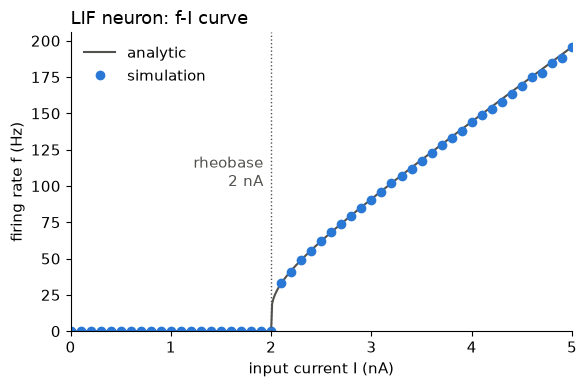

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(currents_fine, rates_theory, color=GRAY, lw=1.5, label="analytic")
ax.plot(currents, rates_sim, "o", color=BLUE, ms=6, label="simulation")
ax.axvline(I_rh, color=GRAY, lw=1, ls=":")
ax.text(I_rh - 0.08, 100, f"rheobase\n{I_rh:g} nA", ha="right", color=GRAY)
ax.set(xlim=(0, 5), ylim=(0, None),
       xlabel="input current I (nA)", ylabel="firing rate f (Hz)")
ax.set_title("LIF neuron: f-I curve", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "lif_fI_curve.png", dpi=150)
plt.show()

## Hodgkin-Huxley model

Same membrane capacitor, but next to the leak there are now a sodium and a potassium channel whose conductances depend on voltage and time (Sect. 2.2, Eqs. 2.4 and 2.5):

$$C\,\frac{du}{dt} = -\Big[g_\mathrm{Na}\,m^3h\,(u-E_\mathrm{Na}) + g_\mathrm{K}\,n^4\,(u-E_\mathrm{K}) + g_L\,(u-E_L)\Big] + I$$

Each gating variable $x \in \{m, h, n\}$ is the fraction of open gates and changes with voltage-dependent opening and closing rates (Eq. 2.9): $\dot{x} = \alpha_x(u)\,(1-x) - \beta_x(u)\,x$.

There is no threshold and no reset: the spikes come out of the equations. We use the original squid-axon parameters of Hodgkin and Huxley (1952), shifted so that the resting potential is −65 mV (the "original parameters" of Fig. 2.7C/D). The cortical parameters of Table 2.1 reproduce the jump of Fig. 2.7B only in part; see the appendix at the end of this notebook.

Units: mV, ms, µF/cm², mS/cm², µA/cm² (mS · mV = µA).

In [9]:
# Original squid-axon parameters (Hodgkin & Huxley 1952), resting potential -65 mV
C_m = 1.0                 # membrane capacitance (uF/cm^2)
g_Na, E_Na = 120.0, 50.0  # sodium: max conductance (mS/cm^2), reversal potential (mV)
g_K, E_K = 36.0, -77.0    # potassium
g_L, E_L = 0.3, -54.387   # leak (E_L chosen so that the resting potential is -65 mV)


# Opening (alpha) and closing (beta) rates of the gates (1/ms), u in mV
def alpha_m(u): return 0.1 * (u + 40) / (1 - np.exp(-(u + 40) / 10))
def beta_m(u): return 4.0 * np.exp(-(u + 65) / 18)
def alpha_h(u): return 0.07 * np.exp(-(u + 65) / 20)
def beta_h(u): return 1 / (1 + np.exp(-(u + 35) / 10))
def alpha_n(u): return 0.01 * (u + 55) / (1 - np.exp(-(u + 55) / 10))
def beta_n(u): return 0.125 * np.exp(-(u + 65) / 80)

Simulation with the same Euler method as for the LIF neuron, now for four variables. The time step is ten times smaller (0.01 ms), because $m$ reacts within about 0.1–0.4 ms.

In [10]:
def simulate_hh(I, T=100.0, dt=0.01):
    """Hodgkin-Huxley neuron with constant input current.

    I  : input current (uA/cm^2)
    T  : simulated time (ms)
    dt : time step (ms)
    Returns time t (ms), membrane potential u (mV) and the gating variables m, h, n.
    """
    n_steps = int(round(T / dt))
    t = np.arange(n_steps) * dt
    u = np.empty(n_steps)
    m = np.empty(n_steps)
    h = np.empty(n_steps)
    n = np.empty(n_steps)

    # start at rest, every gate at its steady-state value x0 = alpha / (alpha + beta)
    u[0] = -65.0
    m[0] = alpha_m(u[0]) / (alpha_m(u[0]) + beta_m(u[0]))
    h[0] = alpha_h(u[0]) / (alpha_h(u[0]) + beta_h(u[0]))
    n[0] = alpha_n(u[0]) / (alpha_n(u[0]) + beta_n(u[0]))

    for k in range(n_steps - 1):
        # ionic currents: Ohm's law with a battery for each channel, Eq. (2.5)
        I_Na = g_Na * m[k]**3 * h[k] * (u[k] - E_Na)
        I_K = g_K * n[k]**4 * (u[k] - E_K)  # potassium current, Eq. (2.5)
        I_L = g_L * (u[k] - E_L)

        # Euler steps: membrane, Eq. (2.4), and gates, Eq. (2.9)
        u[k + 1] = u[k] + dt * (-(I_Na + I_K + I_L) + I) / C_m
        m[k + 1] = m[k] + dt * (alpha_m(u[k]) * (1 - m[k]) - beta_m(u[k]) * m[k])
        h[k + 1] = h[k] + dt * (alpha_h(u[k]) * (1 - h[k]) - beta_h(u[k]) * h[k])
        n[k + 1] = n[k] + dt * (alpha_n(u[k]) * (1 - n[k]) - beta_n(u[k]) * n[k])

    return t, u, m, h, n

The model has no threshold, so counting spikes needs a rule: a spike is an upward crossing of 0 mV. This is only a measuring convention, not part of the model.

In [11]:
def count_spikes(t, u, t_start=0.0):
    """Number of upward crossings of 0 mV after t_start (ms)."""
    up = (u[:-1] < 0) & (u[1:] >= 0)
    return int(np.sum(up & (t[1:] >= t_start)))

Voltage and gates for a constant current of 10 µA/cm², over 50 ms: spike shape, undershoot and the slow gates $h$ and $n$.

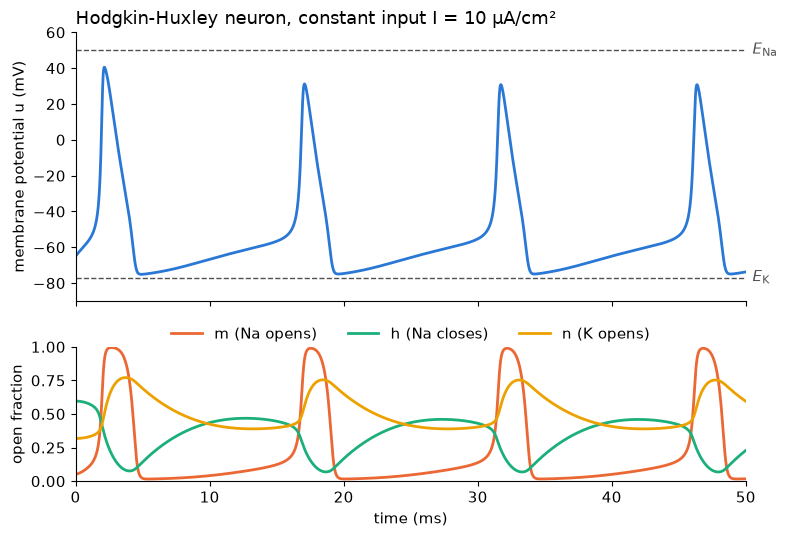

4 spikes in 50 ms; peak 40.5 mV, lowest -75.1 mV


In [12]:
I_hh = 10.0  # input current (uA/cm^2)
T_hh = 50.0  # simulated time (ms)
t, u, m, h, n = simulate_hh(I_hh, T_hh)

fig, (ax_u, ax_g) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1]})
ax_u.plot(t, u, color=BLUE, lw=2)
for E, label in [(E_Na, r"$E_\mathrm{Na}$"), (E_K, r"$E_\mathrm{K}$")]:
    ax_u.axhline(E, color=GRAY, lw=1, ls="--")
    ax_u.text(T_hh + 0.5, E, label, va="center", color=GRAY)
ax_u.set(ylabel="membrane potential u (mV)", ylim=(-90, 60))
ax_u.set_title(f"Hodgkin-Huxley neuron, constant input I = {I_hh:g} µA/cm²", loc="left")

for x, name, color in [(m, "m (Na opens)", ORANGE), (h, "h (Na closes)", AQUA), (n, "n (K opens)", YELLOW)]:
    ax_g.plot(t, x, color=color, lw=2, label=name)
ax_g.set(xlim=(0, T_hh), ylim=(0, 1), xlabel="time (ms)", ylabel="open fraction")
ax_g.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.25))
fig.tight_layout()
fig.savefig(FIG_DIR / f"hh_trace_{I_hh:g}uA.png", dpi=150)
plt.show()

print(f"{count_spikes(t, u)} spikes in {T_hh:.0f} ms; peak {u.max():.1f} mV, lowest {u.min():.1f} mV")

f-I curve of the HH neuron: 0.6 s per current; spikes in the first 0.1 s are not counted, so that a single spike at current onset does not count as firing. This cell takes about 15 seconds.

In [13]:
currents_hh = np.arange(0, 20.5, 0.5)  # input currents (uA/cm^2)
T_fI, t_skip = 600.0, 100.0           # simulated time and skipped start (ms)

rates_hh = []
for current in currents_hh:
    t_sim, u_sim, _, _, _ = simulate_hh(current, T_fI)
    n_spikes = count_spikes(t_sim, u_sim, t_start=t_skip)
    rates_hh.append(n_spikes / ((T_fI - t_skip) / 1000))  # spikes per second (Hz)
rates_hh = np.array(rates_hh)

first = np.argmax(rates_hh > 0)
print(f"no firing up to {currents_hh[first - 1]:g} µA/cm²; "
      f"at {currents_hh[first]:g} µA/cm² already {rates_hh[first]:.0f} Hz")

no firing up to 6 µA/cm²; at 6.5 µA/cm² already 56 Hz


Check of the time step: the HH model has no analytical solution, so we change `dt` and see whether the firing rates change. If halving `dt` changes nothing, `dt = 0.01` ms is small enough. (Rates are counted over 0.5 s, so they are resolved to 2 Hz.)

In [14]:
check_currents = [6.0, 6.5, 10.0, 20.0]  # input currents (uA/cm^2)
check_dts = [0.02, 0.01, 0.005]          # time steps (ms)

print("I (µA/cm²) | rate (Hz) for dt = " + " / ".join(f"{d:g} ms" for d in check_dts))
for current in check_currents:
    rates = []
    for d in check_dts:
        t_sim, u_sim, _, _, _ = simulate_hh(current, T_fI, dt=d)
        rates.append(count_spikes(t_sim, u_sim, t_start=t_skip) / ((T_fI - t_skip) / 1000))
    print(f"{current:10g} | " + " / ".join(f"{r:.0f}" for r in rates))

I (µA/cm²) | rate (Hz) for dt = 0.02 ms / 0.01 ms / 0.005 ms
         6 | 0 / 0 / 0
       6.5 | 56 / 56 / 54
        10 | 68 / 68 / 68
        20 | 86 / 86 / 86


LIF and Hodgkin-Huxley side by side. The currents have different units (nA into one LIF neuron, µA/cm² into a patch of HH membrane), so each model gets its own panel; the firing-rate axis is shared.

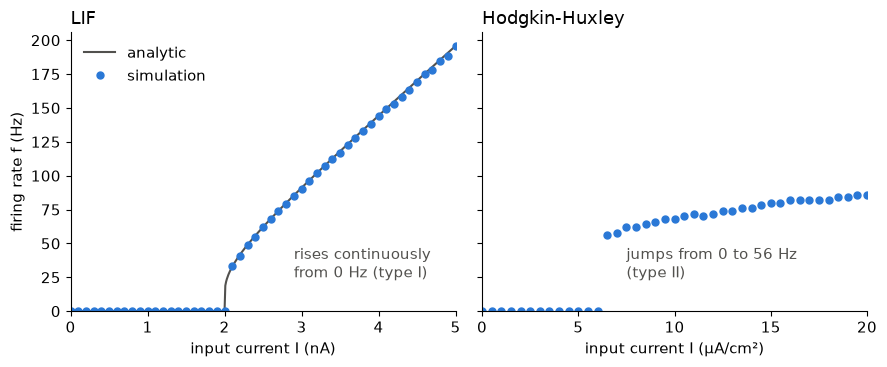

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)

ax1.plot(currents_fine, rates_theory, color=GRAY, lw=1.5, label="analytic")
ax1.plot(currents, rates_sim, "o", color=BLUE, ms=5, label="simulation")
ax1.text(2.9, 25, "rises continuously\nfrom 0 Hz (type I)", color=GRAY)
ax1.set(xlim=(0, 5), ylim=(0, None), xlabel="input current I (nA)", ylabel="firing rate f (Hz)")
ax1.set_title("LIF", loc="left")
ax1.legend(frameon=False, loc="upper left")

ax2.plot(currents_hh, rates_hh, "o", color=BLUE, ms=5)
ax2.text(7.5, 25, "jumps from 0 to 56 Hz\n(type II)", color=GRAY)
ax2.set(xlim=(0, 20), xticks=[0, 5, 10, 15, 20], xlabel="input current I (µA/cm²)")
ax2.set_title("Hodgkin-Huxley", loc="left")

fig.tight_layout()
fig.savefig(FIG_DIR / "fI_lif_vs_hh.png", dpi=150)
plt.show()

## Appendix: Can Table 2.1 reproduce Fig. 2.7B?

The book also gives Hodgkin-Huxley parameters fitted to pyramidal neurons of the cortex (Table 2.1) and shows their f-I curve in Fig. 2.7B: a jump to regular firing at $I_\theta \approx 2.7$ µA/cm² (Sect. 2.2.3). Here we test whether the printed parameters reproduce this, in three steps:

1. compare the table with its own Fig. 2.3,
2. simulate Eq. (2.5) as printed, with $n^4$ in the potassium current,
3. simulate with $n^1$ instead. Table 2.1 takes its $m$ and $n$ rates from the channel model of Mainen et al. (1995); in the published NEURON code of this channel model (ModelDB entry 2488, Mainen & Sejnowski 1996), the potassium conductance is proportional to $n$, not $n^4$.

The parameters get the suffix `_ctx` (cortex), so the squid functions above stay untouched.

In [16]:
# Cortical parameters of Table 2.1 (C_m = 1 uF/cm^2 as above)
g_Na_ctx, E_Na_ctx = 40.0, 55.0  # sodium: max conductance (mS/cm^2), reversal potential (mV)
g_K_ctx, E_K_ctx = 35.0, -77.0   # potassium
g_L_ctx, E_L_ctx = 0.3, -65.0    # leak


# Opening (alpha) and closing (beta) rates (1/ms), u in mV, exactly as printed in Table 2.1
def alpha_n_ctx(u): return 0.02 * (u - 25) / (1 - np.exp(-(u - 25) / 9))
def beta_n_ctx(u): return -0.002 * (u - 25) / (1 - np.exp((u - 25) / 9))
def alpha_m_ctx(u): return 0.182 * (u + 35) / (1 - np.exp(-(u + 35) / 9))
def beta_m_ctx(u): return -0.124 * (u + 35) / (1 - np.exp((u + 35) / 9))
def alpha_h_ctx(u): return 0.25 * np.exp(-(u + 90) / 12)
def beta_h_ctx(u): return 0.25 * np.exp((u + 62) / 6) / np.exp((u + 90) / 12)

Step 1: from the rates, compute the steady state $x_0 = \alpha/(\alpha+\beta)$ and the time constant $\tau_x = 1/(\alpha+\beta)$ (Sect. 2.2.2) and compare them with values read off Fig. 2.3.

In [17]:
def steady_state_and_tau(alpha, beta, u):
    # x0 = alpha / (alpha + beta) and tau = 1 / (alpha + beta), Sect. 2.2.2
    a, b = alpha(u), beta(u)
    return a / (a + b), 1 / (a + b)


u_axis = np.linspace(-100, 100, 2000)  # mV; no point lands exactly on -35 or 25 mV, where the formulas are 0/0
h0_rest, _ = steady_state_and_tau(alpha_h_ctx, beta_h_ctx, -65.0)
_, tau_h = steady_state_and_tau(alpha_h_ctx, beta_h_ctx, u_axis)
_, tau_n = steady_state_and_tau(alpha_n_ctx, beta_n_ctx, u_axis)

print(f"h0 at -65 mV:  {h0_rest:.2f}                      Fig. 2.3A: about 0.6")
print(f"tau_h maximum: {tau_h.max():.1f} ms at {u_axis[tau_h.argmax()]:.0f} mV   Fig. 2.3B: about 20 ms, near -60 mV")
print(f"tau_n maximum: {tau_n.max():.1f} ms at {u_axis[tau_n.argmax()]:.0f} mV    Fig. 2.3B: about 12 ms, near 0 mV")

h0 at -65 mV:  0.62                      Fig. 2.3A: about 0.6
tau_h maximum: 20.6 ms at -62 mV   Fig. 2.3B: about 20 ms, near -60 mV
tau_n maximum: 11.8 ms at -5 mV    Fig. 2.3B: about 12 ms, near 0 mV


The table matches its own Fig. 2.3, so the rate functions themselves are not the problem.

Steps 2 and 3: the same Euler method as above, with the potassium power `p_K` as a parameter. To save time, all currents run at once: `I` is an array, so every line of the Euler step works on all currents in parallel, and `u` gets one column per current.

In [18]:
def simulate_hh_ctx(I, p_K=4, T=600.0, dt=0.01):
    # HH neuron with the cortical parameters of Table 2.1, constant input current.
    # I   : input current(s) (uA/cm^2); an array simulates all currents at once
    # p_K : power of n in the potassium current (4 in Eq. 2.5)
    # Returns time t (ms) and membrane potential u (mV), one column per current.
    I = np.atleast_1d(np.asarray(I, dtype=float))
    n_steps = int(round(T / dt))
    t = np.arange(n_steps) * dt
    u = np.empty((n_steps, len(I)))

    # start at -65 mV, every gate at its steady-state value
    u[0] = -65.0
    m, _ = steady_state_and_tau(alpha_m_ctx, beta_m_ctx, u[0])
    h, _ = steady_state_and_tau(alpha_h_ctx, beta_h_ctx, u[0])
    n, _ = steady_state_and_tau(alpha_n_ctx, beta_n_ctx, u[0])

    for k in range(n_steps - 1):
        I_Na = g_Na_ctx * m**3 * h * (u[k] - E_Na_ctx)
        I_K = g_K_ctx * n**p_K * (u[k] - E_K_ctx)  # the only line that differs between the two runs
        I_L = g_L_ctx * (u[k] - E_L_ctx)

        u[k + 1] = u[k] + dt * (-(I_Na + I_K + I_L) + I) / C_m
        m = m + dt * (alpha_m_ctx(u[k]) * (1 - m) - beta_m_ctx(u[k]) * m)
        h = h + dt * (alpha_h_ctx(u[k]) * (1 - h) - beta_h_ctx(u[k]) * h)
        n = n + dt * (alpha_n_ctx(u[k]) * (1 - n) - beta_n_ctx(u[k]) * n)

    return t, u


def count_spikes_per_column(t, u, t_start=0.0):
    # Like count_spikes above, but for each column of u (one column per current)
    up = (u[:-1] < 0) & (u[1:] >= 0)
    return up[t[1:] >= t_start].sum(axis=0)

f-I curves for $n^4$ and $n^1$, counted as for the squid model: 0.6 s per current, the first 0.1 s skipped. This cell takes about 10 seconds.

In [19]:
currents_ctx = np.arange(0, 10.01, 0.25)  # input currents (uA/cm^2)
rates_ctx = {}

for p in [4, 1]:
    t_sim, u_sim = simulate_hh_ctx(currents_ctx, p_K=p, T=T_fI)
    rates_ctx[p] = count_spikes_per_column(t_sim, u_sim, t_skip) / ((T_fI - t_skip) / 1000)  # Hz
    firing = np.flatnonzero(rates_ctx[p] > 0)
    print(f"n^{p}: fires from {currents_ctx[firing[0]]:g} µA/cm² ({rates_ctx[p][firing[0]]:.0f} Hz) "
          f"to {currents_ctx[firing[-1]]:g} µA/cm² ({rates_ctx[p][firing[-1]]:.0f} Hz)")

n^4: fires from 0.5 µA/cm² (12 Hz) to 2 µA/cm² (38 Hz)
n^1: fires from 1 µA/cm² (24 Hz) to 10 µA/cm² (74 Hz)


Check of the time step for the $n^1$ run, as for the squid model: halving `dt` should not change the rates. This cell takes about 15 seconds.

In [20]:
check_currents_ctx = [1.0, 3.0, 10.0]  # input currents (uA/cm^2)
print("I (µA/cm²) = " + " / ".join(f"{c:g}" for c in check_currents_ctx))
for d in [0.01, 0.005]:
    t_sim, u_sim = simulate_hh_ctx(check_currents_ctx, p_K=1, T=T_fI, dt=d)
    rates = count_spikes_per_column(t_sim, u_sim, t_skip) / ((T_fI - t_skip) / 1000)
    print(f"dt = {d:g} ms: " + " / ".join(f"{r:.0f}" for r in rates) + " Hz")

I (µA/cm²) = 1 / 3 / 10
dt = 0.01 ms: 24 / 42 / 74 Hz
dt = 0.005 ms: 24 / 42 / 74 Hz


Left: voltage at a constant 3 µA/cm², just above the book's jump. Right: both f-I curves; the dotted line marks the jump of Fig. 2.7B at 2.7 µA/cm².

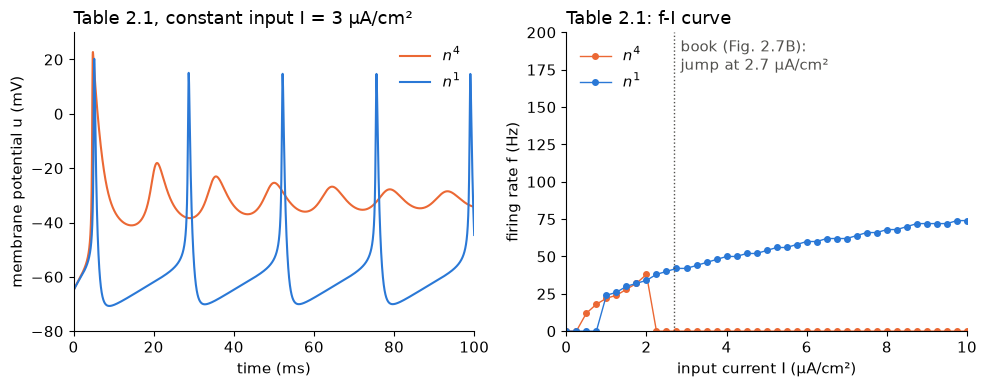

In [21]:
I_demo = 3.0  # input current (uA/cm^2)
fig, (ax_u, ax_f) = plt.subplots(1, 2, figsize=(10, 4))

for p, color in [(4, ORANGE), (1, BLUE)]:
    t_demo, u_demo = simulate_hh_ctx(I_demo, p_K=p, T=100.0)
    ax_u.plot(t_demo, u_demo[:, 0], color=color, lw=1.5, label=f"$n^{p}$")
    ax_f.plot(currents_ctx, rates_ctx[p], "o-", color=color, ms=4, lw=1, label=f"$n^{p}$")

ax_u.set(xlim=(0, 100), ylim=(-80, 30), xlabel="time (ms)", ylabel="membrane potential u (mV)")
ax_u.set_title(f"Table 2.1, constant input I = {I_demo:g} µA/cm²", loc="left")
ax_u.legend(frameon=False, loc="upper right")

ax_f.axvline(2.7, color=GRAY, lw=1, ls=":")
ax_f.text(2.85, 175, "book (Fig. 2.7B):\njump at 2.7 µA/cm²", color=GRAY)
ax_f.set(xlim=(0, 10), ylim=(0, 200), xlabel="input current I (µA/cm²)", ylabel="firing rate f (Hz)")
ax_f.set_title("Table 2.1: f-I curve", loc="left")
ax_f.legend(frameon=False, loc="upper left")

fig.tight_layout()
fig.savefig(FIG_DIR / "table21_check.png", dpi=150)
plt.show()

**Result.** The rate functions of Table 2.1 match Fig. 2.3. With Eq. (2.5) as printed ($n^4$), the potassium current is almost zero: at rest $n_0 \approx 0.0005$, so $n^4 \approx 10^{-13}$. There is no brake after a spike, and above 2 µA/cm² the membrane stays stuck near −30 mV (depolarization block) instead of firing. With $n^1$, as in the published code of the channel model, the spike shape of Fig. 2.7A comes back (peak about +15 mV, undershoot to about −70 mV) and the f-I curve jumps (type II), but between 0.75 and 1 µA/cm² instead of at 2.7 µA/cm², and the rates stay far lower (74 Hz at 10 µA/cm², where Fig. 2.7B shows more than 200 Hz).

So the printed parameters reproduce Fig. 2.7B only in part. The remaining difference must come from details of the book's simulation that are not given in the text. For the main part of this project we therefore use the squid parameters, whose f-I curve matches Fig. 2.7D.